# Bank Marketing · The Complete Previous-Contacts Causal Study
### Observe → quantify uncertainty → adjust → predict → correct → challenge the assumptions

**An organized, executable notebook for your `ml_cloudrun_demo` project.** . The data are the **UCI Bank Marketing additional-full dataset**, not simulated causal evidence.

> **Scientific status:** This is an **observational learning exercise**, not a validated causal study of calling customers. The dataset contains outcomes among people who were contacted in the current campaign, and its candidate customer controls were not documented as historical pre-exposure snapshots. We cannot identify the incremental effect of **contacting vs never contacting** from this dataset.

| Sequence | Question | Method | What it answers |
|:--|:--|:--|:--|
| 1 | What really happened? | Actual CVR, Wilson CI, raw gaps | Descriptive association |
| 2 | What if there were *any* previous calls? | **Binary PLR** and **Binary IRM/AIPW** | Different adjusted binary contrasts |
| 3 | What if we vary the number of previous calls? | **Fixed-dose global CVR / manual PDP** | Model-based scenario curve |
| 4 | How do observations modify that curve? | **Multilevel AIPW** | Propensity-weighted, corrected curve |
| 5 | Can we trust it? | Overlap, ESS, sensitivity, timing | Limits on interpretation |
| Bonus | Do extra calls have one constant slope? | **Numeric PLR** | Single linear benchmark |

**Conventions:** `pp` means *percentage points*. `previous=0` means **no recorded contacts before this campaign**, **not** a customer never contacted in their lifetime. Treat all effects as exploratory adjusted associations unless identification assumptions can be justified.

## 0 · Running this notebook in PyCharm or JupyterLab

From your repo (with `pyproject.toml` already initialized):

```bash
uv add --group train numpy pandas scipy scikit-learn statsmodels matplotlib ipykernel jupyterlab
uv run --group train jupyter lab
```

**Expected dataset:** `<repo>/data/raw/bank.csv`, containing **41,188 rows** from UCI's `bank-additional-full.csv` (semicolon separated). Your earlier project already extracted and renamed this file. To re-download if necessary:

```bash
mkdir -p data/raw
curl -fL 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip' -o data/raw/bank-marketing.zip
python3 - <<'PYCODE'
from io import BytesIO
from zipfile import ZipFile
from pathlib import Path
folder = Path('data/raw')
with ZipFile(folder/'bank-marketing.zip') as outer:
    name = next(x for x in outer.namelist() if x.endswith('bank-additional.zip'))
    with ZipFile(BytesIO(outer.read(name))) as inner:
        name2 = next(x for x in inner.namelist() if x.endswith('bank-additional-full.csv'))
        (folder/'bank.csv').write_bytes(inner.read(name2))
PYCODE
```

The notebook checks the **schema** and refuses to silently use the older UCI `bank-full.csv` (a different dataset). Optional: set environment variable `BANK_CSV=/full/path/to/bank.csv` before launching Jupyter.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep

SEED, FOLDS = 42, 3
CANDIDATE_FILES = [p / 'data/raw/bank.csv' for root in [Path.cwd()] for p in [root, *root.parents]]
path = Path(os.environ['BANK_CSV']) if os.getenv('BANK_CSV') else next(
    (p for p in CANDIDATE_FILES if p.exists()), None
)
if path is None or not path.is_file():
    raise FileNotFoundError('Missing data/raw/bank.csv. Follow the download instructions in the previous Markdown cell.')

df = pd.read_csv(path, sep=';')
required = {'age','job','marital','education','default','housing','loan',
            'previous','pdays','poutcome','campaign','duration','y', 'day_of_week'}
if not required.issubset(df.columns):
    raise ValueError(f'Expected UCI bank-additional-full schema. Missing {sorted(required-set(df))}.')
if not df['y'].isin(['yes','no']).all() or not df['previous'].ge(0).all():
    raise ValueError('Unexpected target labels or negative previous-contact counts.')

df['subscribed'] = df['y'].eq('yes').astype(int)
df['any_previous'] = df['previous'].gt(0).astype(int)
N = len(df)
print(f'Data: {path} | records: {N:,} | subscription CVR: {df.subscribed.mean():.2%}')
print('Actual downloaded UCI data: expected 41,188 records; any other count needs investigation.')
display(df[['age','job','previous','campaign','duration','subscribed']].head())

Data: /home/chaka/projects/ml_cloudrun_demo/data/raw/bank.csv | records: 41,188 | subscription CVR: 11.27%
Actual downloaded UCI data: expected 41,188 records; any other count needs investigation.


,age,job,previous,campaign,duration,subscribed
0,56,housemaid,0,1,261,0
1,57,services,0,1,149,0
2,37,services,0,1,226,0
3,40,admin.,0,1,151,0
4,56,services,0,1,307,0


## 1 · Define the estimand, time order, and causal diagram **before modeling**

**Our observed outcome** is whether a **current-campaign contact record** ended in a term-deposit subscription ($Y=1$). The previous-contact count $D$ is the **number of contacts made before this current campaign**. Our binary treatment is $T=\mathbf 1(D>0)$.

```text
Past, unrecorded customer traits U ─────► Earlier contact policy D ─────► Current Y
               │                                  ▲                  ▲
               └──────────────────────────────────┴──────────────────┘
                       unmeasured selection and responsiveness

Candidate observed X (age, job, loans...) was recorded in the current dataset.
It is NOT verified to have been measured before the earlier contacts.
```

To claim $E[Y(d)-Y(0)]$ as a *causal* contrast, we'd need **well-defined interventions**, **consistency**, **no unmeasured pre-treatment confounding** ($Y(d)\perp D\mid X$), **overlap** ($P(D=d\mid X)>0$ on the target population), sound observation units, and no problematic interference. **These are not established here.**

**Not usable as historical baseline confounders:** `duration` (after/during current call), `campaign`, `contact`, `month`, `day_of_week` (current-campaign information), `pdays`/`poutcome` (prior-campaign history that can be downstream of past contacts). Macroeconomic series here are current-record values, not verified old snapshots.

**Avoid two incorrect conclusions:** (1) `previous = 0` is not a never-contacted holdout from the current campaign. (2) A narrow CI after DML does not prove we measured all confounders.

## 2 · Data audit and actual CVR — **no ML yet**

For exact $d$ past contacts, the observed conversion rate is just a fraction:

$$
\boxed{\widehat{CVR}_{obs}(d)=\frac{\#\text{subscriptions among records with }D=d}{\#\text{records with }D=d}}
$$

A **Wilson 95% interval** quantifies sampling uncertainty around each observed proportion; it does **not** adjust for confounding or convert the association into causation. With very small $n$, intervals will be wide.

In [3]:
print('Missing values in teaching features:')
display(df[['age','job','marital','education','default','housing','loan','previous']].isna().sum().to_frame('null_count').T)
print('Unknown categorical labels (these are values, not NaN):')
display(pd.Series({c: int(df[c].eq('unknown').sum()) for c in
                   ['job','marital','education','default','housing','loan']}, name='unknown_count'))

raw_d = df.groupby('previous')['subscribed'].agg(n='size', bookings='sum', cvr='mean')
raw_d['ci_low'], raw_d['ci_high'] = proportion_confint(
    raw_d['bookings'], raw_d['n'], method='wilson'
)
raw_d['raw_gap_vs_0_pp'] = 100*(raw_d['cvr']-raw_d.loc[0,'cvr'])
print('All observed counts (rare tails included):')
display(raw_d.assign(observed_CVR_pct=100*raw_d.cvr,
                     Wilson_low_pct=100*raw_d.ci_low,
                     Wilson_high_pct=100*raw_d.ci_high)[
  ['n','bookings','observed_CVR_pct','Wilson_low_pct','Wilson_high_pct','raw_gap_vs_0_pp']
].round(2))

Missing values in teaching features:


,age,job,marital,education,default,housing,loan,previous
null_count,0,0,0,0,0,0,0,0


Unknown categorical labels (these are values, not NaN):


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
Name: unknown_count, dtype: int64

All observed counts (rare tails included):


,n,bookings,observed_CVR_pct,Wilson_low_pct,Wilson_high_pct,raw_gap_vs_0_pp
previous,,,,,,
0,35563,3141,8.83,8.54,9.13,0.00
1,4561,967,21.20,20.04,22.41,12.37
2,754,350,46.42,42.89,49.99,37.59
3,216,128,59.26,52.60,65.59,50.43
4,70,38,54.29,42.70,65.43,45.45
5,18,13,72.22,49.13,87.50,63.39
6,5,3,60.00,23.07,88.24,51.17
7,1,0,0.00,0.00,79.35,-8.83


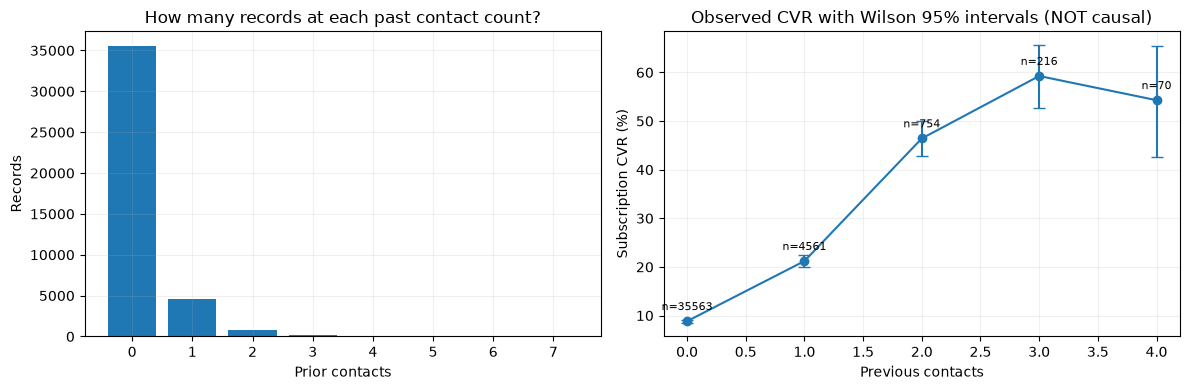

In [4]:
view = raw_d[(raw_d.index <= 7) & (raw_d['n'] >= 20)].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(raw_d.index[raw_d.index<=7], raw_d.loc[raw_d.index<=7, 'n'])
axes[0].set(title='How many records at each past contact count?', xlabel='Prior contacts', ylabel='Records')
axes[1].errorbar(view.index, 100*view.cvr,
  yerr=[100*(view.cvr-view.ci_low), 100*(view.ci_high-view.cvr)],
  marker='o', capsize=4, ls='-')
for d, row in view.iterrows():
    axes[1].annotate(f'n={int(row.n)}', (d,100*row.cvr), xytext=(0,8),
                     textcoords='offset points', ha='center', fontsize=8)
axes[1].set(title='Observed CVR with Wilson 95% intervals (NOT causal)',
            xlabel='Previous contacts', ylabel='Subscription CVR (%)')
for ax in axes: ax.grid(alpha=.18)
fig.tight_layout(); plt.show()

### 2B · Binary raw association: any previous contact vs none

Define $T=0$ when `previous=0` and $T=1$ when `previous>=1`. The **raw percentage-point gap** is:

$$
\boxed{\Delta_{raw}=100\big[CVR_{obs}(T=1)-CVR_{obs}(T=0)\big]\;\text{pp}}
$$

For independent binomial samples, **Newcombe's interval** uses the two groups' Wilson intervals to quantify uncertainty around this raw gap. It is **not** a confounding adjustment. This independence approximation may be imperfect because the release has no unique customer ID to verify record independence.

In [6]:
raw_binary = df.groupby('any_previous')['subscribed'].agg(n='size', bookings='sum', cvr='mean')
a, b = raw_binary.loc[1], raw_binary.loc[0]
raw_gap = float(a.cvr-b.cvr)
ci_gap = confint_proportions_2indep(
    int(a.bookings), int(a.n), int(b.bookings), int(b.n),
    compare='diff', method='newcomb'
)
display(raw_binary.rename(index={0:'No prior contact',1:'At least one prior contact'})
        .assign(CVR_pct=lambda t:100*t.cvr).round(3))
print(f'Raw binary gap: {100*raw_gap:+.2f} pp')
print(f'Approx raw 95% Newcombe CI: [{100*ci_gap[0]:+.2f}, {100*ci_gap[1]:+.2f}] pp')
print('Interpretation: an observed association, NOT the effect of making a call.')

,n,bookings,cvr,CVR_pct
any_previous,,,,
No prior contact,35563,3141,0.088,8.832
At least one prior contact,5625,1499,0.266,26.649


Raw binary gap: +17.82 pp
Approx raw 95% Newcombe CI: [+16.64, +19.02] pp
Interpretation: an observed association, NOT the effect of making a call.


## 3 · Define **candidate adjustment features**, not guaranteed confounders

We use `age`, `job`, `marital`, `education`, `default`, `housing`, and `loan` **only as teaching proxies**. They are observed on the released current-contact records, with no guarantee that they were measured before past calls. This means our adjusted estimates **remain exploratory**.

The model pipeline will: (a) impute missing numeric values and scale them, (b) impute categorical values and one-hot encode them, and (c) fit logistic regression. All preprocessing is trained **inside the training folds**, preventing train/test preprocessing leakage.

We'll reuse this same `classifier()` for propensity, outcome, and global-CVR models. For a count regression in PLR we use a `Ridge` regressor.

In [9]:
NUM = ['age']
CAT = ['job','marital','education','default','housing','loan']
FEATURES = NUM + CAT

def preprocessing(extra_cat=()):
    return ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), NUM),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), CAT + list(extra_cat)),
    ])

def classifier(extra_cat=()):
    return Pipeline([
        ('preprocessing', preprocessing(extra_cat)),
        ('logistic', LogisticRegression(max_iter=1200)),
    ])

def numeric_regressor():
    return Pipeline([
        ('preprocessing', preprocessing()),
        ('ridge', Ridge(alpha=10.)),
    ])

X = df[FEATURES].copy()
Y = df['subscribed'].to_numpy(dtype=float)
T = df['any_previous'].to_numpy(dtype=int)
print(f'Prepared X: {X.shape}; Y: {Y.shape}; T: {T.shape}')

Prepared X: (41188, 7); Y: (41188,); T: (41188,)


# PART I · Binary previous contact: DML-PLR versus DML-IRM

We ask **one question**: *How do observed subscription outcomes differ between previously contacted and nonpreviously contacted records, after proxy adjustment?*

The four fitted models per fold are **not** four estimators:

| Model | Training rows | Prediction |
|---|---|---|
| `assignment` | All training records | $\hat e(X)=P(T=1\mid X)$ |
| `overall_y_model` | All training records | $\hat\ell(X)=E[Y\mid X]$, for PLR |
| `model0` | Training records **with $T=0$ only** | $\hat\mu_0(X)=E[Y\mid X,T=0]$ |
| `model1` | Training records **with $T=1$ only** | $\hat\mu_1(X)=E[Y\mid X,T=1]$ |

**Cross-fitting:** Split records into 3 folds, fit on 2 folds and predict on the untouched 3rd. Each record receives held-out predictions. The **same $\hat e$** is used in PLR and IRM.

In [11]:
# Four fitted models per fold; the three IRM models are assignment/model0/model1.
p_hat, yhat, mu0, mu1 = (np.empty(N) for _ in range(4))
cv_binary = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)

for train, test in cv_binary.split(X, T):
    # 1. Predict treatment selection using all training records.
    assignment = classifier().fit(X.iloc[train], T[train])
    p_hat[test] = assignment.predict_proba(X.iloc[test])[:, 1]

    # 2. Predict outcomes overall using all training records (PLR only).
    overall_y_model = classifier().fit(X.iloc[train], Y[train])
    yhat[test] = overall_y_model.predict_proba(X.iloc[test])[:, 1]

    # 3. Filter training records by actual treatment (IRM only).
    train_0 = train[T[train] == 0]
    train_1 = train[T[train] == 1]

    model0 = classifier().fit(X.iloc[train_0], Y[train_0])
    model1 = classifier().fit(X.iloc[train_1], Y[train_1])

    # Both models predict on the SAME held-out records.
    mu0[test] = model0.predict_proba(X.iloc[test])[:, 1]
    mu1[test] = model1.predict_proba(X.iloc[test])[:, 1]

print(f'Treatment propensity range: [{p_hat.min():.4f}, {p_hat.max():.4f}]')
print('Each record now has p_hat, yhat, mu0, and mu1 from held-out models.')

Treatment propensity range: [0.0347, 0.4793]
Each record now has p_hat, yhat, mu0, and mu1 from held-out models.


## 4 · Binary **DML-PLR** — one adjusted slope

PLR asks for **one additive coefficient** $\theta$ linking the treatment to the outcome. First subtract what $X$ predicts:

$$
R_T=T-\hat e(X), \qquad R_Y=Y-\hat\ell(X)
$$

Then regress residual outcome on residual treatment:

$$
\boxed{\hat\theta_{PLR}=\frac{\sum_i R_{T,i}R_{Y,i}}{\sum_i R_{T,i}^2}}
$$

**Reading:** $\hat\theta=0.02$ means **+2 pp** under a valid additive PLR causal model. With heterogeneous effects, a binary PLR coefficient generally targets an **overlap-weighted effect**, not necessarily the population ATE of IRM. Here neither is causally validated.

In [13]:
r_t = T-p_hat
r_y = Y-yhat
plr = np.sum(r_t*r_y) / np.sum(r_t**2)
# Approximate influence-function standard error (not cluster-robust).
phi_plr = r_t*(r_y-plr*r_t) / np.mean(r_t**2)
se_plr = phi_plr.std(ddof=1)/np.sqrt(N)
print(f'Binary PLR = {100*plr:+.2f} pp')
print(f'Approx 95% CI = [{100*(plr-1.96*se_plr):+.2f}, {100*(plr+1.96*se_plr):+.2f}] pp')

Binary PLR = +15.61 pp
Approx 95% CI = [+14.44, +16.78] pp


## 5 · Binary **DML-IRM / AIPW** — model difference **plus** weighted correction

The model-only effect (**G-computation**) averages predicted subscriptions under the two possibilities:

$$
\widehat{ATE}_{G}=\frac1N\sum_i[\hat\mu_1(X_i)-\hat\mu_0(X_i)]
$$

AIPW adds **observed prediction errors**, weighted by the chance of being in the observed group:

$$
\boxed{\widehat{ATE}_{AIPW}=\frac1N\sum_i\left[
\underbrace{\hat\mu_{1i}-\hat\mu_{0i}}_{\text{model-based effect}}
+\underbrace{\frac{T_i(Y_i-\hat\mu_{1i})}{\hat e_i}}_{\text{treated correction}}
-\underbrace{\frac{(1-T_i)(Y_i-\hat\mu_{0i})}{1-\hat e_i}}_{\text{control correction}}
\right]}
$$

**Symbols:** $Y_i$ = 0/1 actual subscription; $T_i$ = whether previously contacted; $\hat\mu_1,\hat\mu_0$ = outcome probabilities from separate models; $\hat e_i$ = predicted treatment probability. Dividing by $e$ is **inverse probability weighting**. This supports double robustness under identification and regularity assumptions—**not guaranteed accuracy in each dataset**.

For stability, we show a clearly labeled **sensitivity choice**: a 1% probability floor. Such truncation can introduce bias and cannot solve missing overlap.

In [15]:
BINARY_FLOOR = 0.01  # sensitivity choice, NOT a fix for lack of overlap
p = np.clip(p_hat, BINARY_FLOOR, 1-BINARY_FLOOR)
base_i = mu1-mu0
corr_treated_i = T*(Y-mu1)/p
corr_control_i = (1-T)*(Y-mu0)/(1-p)
correction_i = corr_treated_i-corr_control_i
score_i = base_i+correction_i

base, treated, control = base_i.mean(), corr_treated_i.mean(), corr_control_i.mean()
irm, se_irm = score_i.mean(), score_i.std(ddof=1)/np.sqrt(N)

components = pd.Series({
    'Base G-computation (pp)':100*base,
    'Plus treated correction (pp)':100*treated,
    'Minus control correction (pp)':-100*control,
    'Net AIPW correction (pp)':100*correction_i.mean(),
    'Final IRM/AIPW (pp)':100*irm,
})
display(components.round(3).to_frame('value'))
assert np.allclose(base + treated-control, irm)
print(f'Approx IRM 95% CI: [{100*(irm-1.96*se_irm):+.2f}, {100*(irm+1.96*se_irm):+.2f}] pp')

,value
Base G-computation (pp),14.073
Plus treated correction (pp),0.110
Minus control correction (pp),-0.015
Net AIPW correction (pp),0.095
Final IRM/AIPW (pp),14.168


Approx IRM 95% CI: [+13.04, +15.30] pp


### 5B · Compare **all five** binary estimators

- **Raw gap:** group averages; no adjustment.
- **G-computation:** just the two outcome models.
- **IPW:** observed outcomes with inverse-propensity weights.
- **DML-PLR:** cross-fitted residual slope.
- **DML-IRM/AIPW:** G-computation + weighted error correction.

**Never choose an estimator just because it reports the biggest, smallest, or most significant effect.** The target parameter, study design, and uncertainty matter more.

In [16]:
ipw = np.mean(T*Y/p - (1-T)*Y/(1-p))
comparison = pd.DataFrame({
    'method':['Raw association', 'G-computation', 'IPW (floored)',
              'Binary DML-PLR', 'Binary DML-IRM/AIPW (floored)'],
    'estimated_difference_pp':100*np.array([raw_gap, base, ipw, plr, irm]),
    'causally_verified':['No']*5,
})
display(comparison.round(3))
print('Interpretation: these are adjusted/descriptive comparisons; none proves that an earlier call caused a subscription.')

,method,estimated_difference_pp,causally_verified
0,Raw association,17.817,No
1,G-computation,14.073,No
2,IPW (floored),14.193,No
3,Binary DML-PLR,15.608,No
4,Binary DML-IRM/AIPW (floored),14.168,No


Interpretation: these are adjusted/descriptive comparisons; none proves that an earlier call caused a subscription.


## 6 · Binary overlap diagnostics: **can we fairly compare similar customers?**

Overlap means customers with similar *genuine baseline* $X$ could have received either treatment. A model output strictly between 0 and 1 does **not** prove overlap. Very small propensities create large $1/e$ weights.

**Effective sample size (ESS)** for weights $w$ is:

$$\boxed{ESS=\frac{(\sum_iw_i)^2}{\sum_iw_i^2}}$$

A small ESS relative to the raw group size warns that a few heavily weighted records dominate the estimate. Here the measured $X$ itself is not verified as historical baseline.

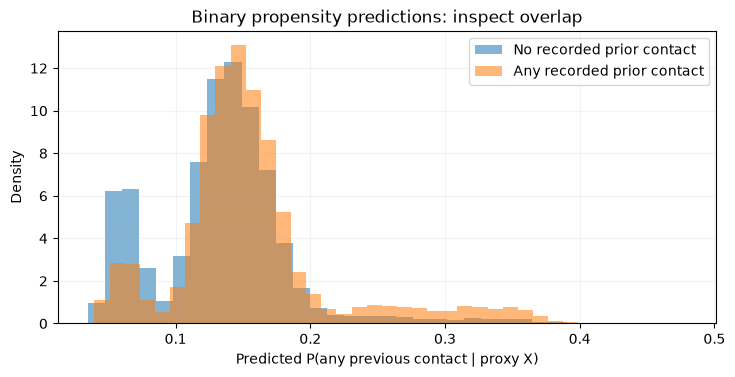

Treated: raw n=5,625, effective n≈4,685
Controls: raw n=35,563, effective n≈35,413
Fraction predicted p<0.025: 0.00%
Fraction predicted p>0.975: 0.00%


In [18]:
fig, ax = plt.subplots(figsize=(8.5,3.8))
for t, label in [(0,'No recorded prior contact'), (1,'Any recorded prior contact')]:
    ax.hist(p_hat[T==t], bins=35, alpha=.55, density=True, label=label)
ax.set(title='Binary propensity predictions: inspect overlap', xlabel='Predicted P(any previous contact | proxy X)', ylabel='Density')
ax.legend(); ax.grid(alpha=.15); plt.show()

def effective_n(w):
    return float(w.sum()**2 / (w*w).sum())

w1 = 1/p[T==1]
w0 = 1/(1-p[T==0])
print(f'Treated: raw n={len(w1):,}, effective n≈{effective_n(w1):,.0f}')
print(f'Controls: raw n={len(w0):,}, effective n≈{effective_n(w0):,.0f}')
print(f'Fraction predicted p<0.025: {(p_hat<.025).mean():.2%}')
print(f'Fraction predicted p>0.975: {(p_hat>.975).mean():.2%}')

In [19]:
# Changing propensity floors changes weights, not the observational design.
rows = []
for floor in [.005, .01, .025, .05, .10]:
    ef = np.clip(p_hat, floor, 1-floor)
    sc = base_i + T*(Y-mu1)/ef - (1-T)*(Y-mu0)/(1-ef)
    rows.append({'propensity_floor':floor, 'IRM_estimate_pp':100*sc.mean()})
display(pd.DataFrame(rows).round(3))
print('Large changes across floors signal unstable adjustment. Trimming never manufactures overlap.')

,propensity_floor,IRM_estimate_pp
0,0.005,14.168
1,0.010,14.168
2,0.025,14.168
3,0.050,14.160
4,0.100,14.153


Large changes across floors signal unstable adjustment. Trimming never manufactures overlap.


# PART II · Exact past-contact counts: actual → fixed PDP → discrete AIPW

We focus on **exact** previous-contact counts $D\in\{0,1,2,3\}$, but keep **every record** in our target population. All other records form a separate nuisance category **`4+`**, which the model learns as an observed category. This avoids selecting our target population using the post-baseline dose actually received.

**Important:** `4+` means **at least four** past contacts, not exactly four. We estimate fixed scenarios only for exact 0, 1, 2, and 3, and keep the same full population for PDP and AIPW. This still does **not establish causality**: genuine pre-exposure common causes, dynamic call policies and selection into the current campaign remain unresolved.

In [20]:
DOSES = np.array([0,1,2,3], dtype=int)
# Entire current-campaign cohort remains in the target population.
study = df.copy().reset_index(drop=True)
X_d = study[FEATURES].copy()
Y_d = study['subscribed'].to_numpy(dtype=float)
D_d = study['previous'].to_numpy(dtype=int)   # actual EXACT counts, including 4,5,...
G_d = study['previous'].clip(upper=4).astype(str).replace({'4':'4+'}).to_numpy()
n_d = len(study)
counts_d = np.array([(D_d==d).sum() for d in DOSES])
print(f'Multi-dose target population: all {n_d:,} records.')
print('Exact dose counts 0, 1, 2, 3:', dict(zip(DOSES,counts_d)))
print('Remaining 4+ category:', int((D_d>=4).sum()))
if (counts_d < 30).any():
    raise ValueError('At least one exact dose has fewer than 30 records; a separate AIPW curve is not reasonable.')

Multi-dose target population: all 41,188 records.
Exact dose counts 0, 1, 2, 3: {np.int64(0): np.int64(35563), np.int64(1): np.int64(4561), np.int64(2): np.int64(754), np.int64(3): np.int64(216)}
Remaining 4+ category: 94


## 7 · Raw dose-response (actual subscriptions only)

The observed $CVR_{obs}(d)$ is simply subscriptions divided by records at dose $d$. The raw **gap versus zero** is $100[CVR_{obs}(d)-CVR_{obs}(0)]$ pp, and the observed **increment** is $100[CVR_{obs}(d)-CVR_{obs}(d-1)]$ pp. **Neither is a causal lift.**

In [21]:
observed_d = study.groupby('previous')['subscribed'].agg(n='size', subscriptions='sum', observed='mean').reindex(DOSES)
observed_d['gap_vs_0_pp'] = 100*(observed_d.observed - observed_d.observed.iloc[0])
observed_d['adjacent_gap_pp'] = 100*observed_d.observed.diff()
display(observed_d.assign(observed_CVR_pct=100*observed_d.observed).drop(columns='observed').round(3))

,n,subscriptions,gap_vs_0_pp,adjacent_gap_pp,observed_CVR_pct
previous,,,,,
0,35563,3141,0.000,NaN,8.832
1,4561,967,12.369,12.369,21.201
2,754,350,37.587,25.218,46.419
3,216,128,50.427,12.840,59.259


## 8 · Train ONE global CVR model and fix the past-contact dose for everyone (PDP)

We fit **one** outcome model:

$$\hat g(X,D)=\widehat{P}(Y=1\mid X,D)$$

For each target exact dose $d$, **replace $D$ by $d$ for every held-out record**, predict, then average all predictions:

$$
\boxed{\widehat{CVR}_{PDP}(d)=\frac1N\sum_{i=1}^{N}\hat g_{-fold(i)}(X_i,d)}
$$

This is manual **Partial Dependence** (fixed-dose global CVR). It describes a *model scenario*, not an identified causal intervention. Cross-fitting avoids scoring records using the model fitted on those same rows.

**We also fit a multinomial propensity model** $\hat e_d(X)=P(D=d\mid X)$ on the same training folds. It learns five categories **0, 1, 2, 3 and 4+**, but we display estimates only for the four exact doses. **The exact same held-out CVR predictions are used in the AIPW correction in the next section.**

In [24]:
# Matrices: one row per bank record, one column per exact dose 0/1/2/3.
mu_d = np.empty((n_d, len(DOSES)))  # global model's fixed-dose CVR predictions
prop_d = np.empty((n_d, len(DOSES)))  # dose assignment probabilities
cv_d = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED+1)

for train, test in cv_d.split(X_d, G_d):
    # Outcome model sees 0/1/2/3/4+ actual categories.
    training = X_d.iloc[train].assign(dose=G_d[train])
    global_cvr = classifier(extra_cat=['dose']).fit(training, Y_d[train])

    # Propensity P(D=d|X) trained on all five categories, on training fold only.
    assignment = classifier().fit(X_d.iloc[train], G_d[train])
    class_order = assignment.named_steps['logistic'].classes_
    prob_fold = assignment.predict_proba(X_d.iloc[test])

    for j, dose in enumerate(DOSES):
        fixed = X_d.iloc[test].assign(dose=str(dose))
        mu_d[test, j] = global_cvr.predict_proba(fixed)[:, 1]
        prop_d[test, j] = prob_fold[:, np.flatnonzero(class_order==str(dose))[0]]

model_curve = mu_d.mean(axis=0)
print('Fixed-dose predicted CVR (PDP), full population:')
display(pd.DataFrame({'exact_previous_contacts':DOSES,
                      'PDP_CVR_pct':100*model_curve}).round(3))

Fixed-dose predicted CVR (PDP), full population:


,exact_previous_contacts,PDP_CVR_pct
0,0,9.081
1,1,19.368
2,2,38.337
3,3,49.127


### 8B · See *exactly* what fixing a dose means

Each record gets **four predicted CVRs**: what its model predicts at 0, 1, 2, and 3 prior contacts, holding its candidate $X$ the same. We never observe all four potential outcomes in reality; these are only model predictions.

In [25]:
example = pd.DataFrame(mu_d[:5], columns=[f'pred_CVR_d{d}' for d in DOSES])
example.insert(0, 'actual_previous', D_d[:5])
example.insert(1, 'actual_subscribed', Y_d[:5].astype(int))
display(example.round(3))
print('To estimate PDP at dose 2, take the mean of column pred_CVR_d2 over ALL study records.')

,actual_previous,actual_subscribed,pred_CVR_d0,pred_CVR_d1,pred_CVR_d2,pred_CVR_d3
0,0,0,0.105,0.225,0.431,0.598
1,0,0,0.037,0.087,0.210,0.262
2,0,0,0.072,0.162,0.334,0.497
3,0,0,0.102,0.217,0.430,0.537
4,0,0,0.070,0.156,0.341,0.409


To estimate PDP at dose 2, take the mean of column pred_CVR_d2 over ALL study records.


## 9 · Fixed-dose changes and slopes — still predictive, not causal

For adjacent **integer doses** $d\to d+1$:

$$
\boxed{\text{PDP slope}_{d\to d+1}=100\,[\widehat{CVR}_{PDP}(d+1)-\widehat{CVR}_{PDP}(d)]\ \text{pp/call}}
$$

A slope of $+2$ pp per call is the model's **predicted change** between these two scenarios. It is **not price elasticity**, and the count can only be integers.

In [27]:
slopes = pd.DataFrame({
    'from_to':[f'{d} → {d+1}' for d in DOSES[:-1]],
    'PDP_slope_pp_per_call':100*np.diff(model_curve),
    'relative_predicted_CVR_change_pct':100*np.diff(model_curve)/model_curve[:-1]
})
display(slopes.round(3))

,from_to,PDP_slope_pp_per_call,relative_predicted_CVR_change_pct
0,0 → 1,10.287,113.275
1,1 → 2,18.970,97.944
2,2 → 3,10.790,28.145


## 10 · Discrete AIPW — **correct the exact same PDP predictions**

At one exact dose $d$ we start with $PDP(d)$ and add an observed-outcome correction:

$$
\boxed{
\widehat{CVR}_{AIPW}(d)=
\underbrace{\frac1N\sum_i\hat g(X_i,d)}_{\text{model CVR / PDP}}
+\underbrace{\frac1N\sum_i
\frac{\mathbf1(D_i=d)}{\hat e_d(X_i)}
\big[Y_i-\hat g(X_i,d)\big]}_{\text{weighted correction}}
}
$$

**For every record:** $\mathbf1(D_i=d)$ is **1 only if the record actually received exact dose $d$**. $\hat e_d(X_i)$ is the estimated conditional probability of that dose; the `4+` category is still included in the assignment model. $Y_i-\hat g(X_i,d)$ is actual subscription minus predicted subscription.

Taking the `mean` over **ALL** $N$ records already includes the relative number assigned each exact dose. **Don't multiply by $n_{dose}/N$ again.** In genuine randomized experiments you would use the logged assignment probabilities instead of estimating them.

**We use a displayed, prespecified 1% propensity floor solely for exploratory sensitivity.** Truncation can bias the estimate and cannot create true overlap.

In [28]:
DOSE_FLOOR = .01  # sensitivity choice; does not create causal overlap
hit = D_d[:,None] == DOSES[None,:]            # one Boolean indicator per dose
safe_prop = np.maximum(prop_d, DOSE_FLOOR)
error_d = Y_d[:,None] - mu_d
correction_rows = hit * error_d / safe_prop      # shape: n_records × 4
aipw_scores = mu_d + correction_rows

correction_curve = correction_rows.mean(axis=0)
aipw_curve = aipw_scores.mean(axis=0)
se_d = aipw_scores.std(axis=0, ddof=1)/np.sqrt(n_d)
assert np.allclose(aipw_curve, model_curve+correction_curve)

curve_table = pd.DataFrame({
    'previous_exact': DOSES,
    'observed_n': counts_d,
    'Observed_CVR_pct':100*observed_d.observed.to_numpy(),
    'PDP_CVR_pct':100*model_curve,
    'AIPW_correction_pp':100*correction_curve,
    'AIPW_CVR_pct':100*aipw_curve,
    'Approx_CI_low_pct':100*(aipw_curve-1.96*se_d),
    'Approx_CI_high_pct':100*(aipw_curve+1.96*se_d),
})
display(curve_table.round(3))
print('NOTE: AIPW corrections and approximate CIs here are not validated causal effects.')

,previous_exact,observed_n,Observed_CVR_pct,PDP_CVR_pct,AIPW_correction_pp,AIPW_CVR_pct,Approx_CI_low_pct,Approx_CI_high_pct
0,0,35563,8.832,9.081,0.021,9.102,8.799,9.405
1,1,4561,21.201,19.368,-0.143,19.224,18.099,20.349
2,2,754,46.419,38.337,0.812,39.149,35.710,42.589
3,3,216,59.259,49.127,0.414,49.542,46.426,52.658


NOTE: AIPW corrections and approximate CIs here are not validated causal effects.


### 10B · Small calculation from **real rows** (one exact contact count)

At $d=1$, the following cell selects the first **two actual receivers**, printing their individual residuals, propensities and contributions. The full correction uses *every* bank record:

$$
Correction(1)=\frac{\sum_{i:D_i=1}\big[Y_i-\hat g(X_i,1)\big]/\hat e_1(X_i)}{N}
$$

This demonstrates where the **sum** and **division by total $N$** happen. The displayed two receivers do not themselves determine the estimate.

In [29]:
j = 1  # target exact previous-contact dose = 1
receivers = np.flatnonzero(D_d==DOSES[j])[:2]
example_errors = pd.DataFrame({
    'Y_actual': Y_d[receivers].astype(int),
    'pred_if_d1': mu_d[receivers,j],
    'p_receiving_d1': prop_d[receivers,j],
    'inverse_p_weight_used':1/safe_prop[receivers,j],
    'weighted_error':correction_rows[receivers,j],
}, index=[f'record_{i}' for i in receivers])
display(example_errors.round(4))
print(f'PDP(1): {model_curve[j]:.3%}')
print(f'Correction(1): {correction_rows[:,j].sum()/n_d:+.4f}')
print(f'Corrected AIPW CVR(1): {aipw_curve[j]:.3%}')

,Y_actual,pred_if_d1,p_receiving_d1,inverse_p_weight_used,weighted_error
record_24013,0,0.2198,0.1459,6.8537,-1.5064
record_24019,1,0.1561,0.1310,7.6327,6.4409


PDP(1): 19.368%
Correction(1): -0.0014
Corrected AIPW CVR(1): 19.224%


## 11 · Contrasts on the **same full population**

For each exact dose $d$, the adjusted **contrast versus 0** is:

$$
\boxed{\widehat\Delta(d,0)=\frac1N\sum_i\left[\psi_{i,d}-\psi_{i,0}\right]}
$$

where $\psi_{i,d}$ is the individual AIPW score in the previous cell. To estimate uncertainty in the contrast, use the **per-row paired score difference**, not independent error bars on two separate curves. These intervals are only **approximate**, omit unknown repeated-customer clustering, and do not solve invalid causal assumptions.

In [31]:
contrasts = []
for j,d in enumerate(DOSES[1:],start=1):
    pair = aipw_scores[:,j] - aipw_scores[:,0]
    mean, se = pair.mean(), pair.std(ddof=1)/np.sqrt(n_d)
    contrasts.append({'contrast':f'{d} vs 0', 'estimated_gap_pp':100*mean,
                      'approx_95_low_pp':100*(mean-1.96*se),
                      'approx_95_high_pp':100*(mean+1.96*se)})
display(pd.DataFrame(contrasts).round(3))

,contrast,estimated_gap_pp,approx_95_low_pp,approx_95_high_pp
0,1 vs 0,10.122,8.960,11.284
1,2 vs 0,30.047,26.596,33.499
2,3 vs 0,40.439,37.310,43.569


## 12 · Compare all **three CVR curves** in one chart

- **Observed:** actual subscription fraction among records at dose $d$ (different groups).
- **PDP:** average global-model predictions if **every** study record were assigned $d$ (same population).
- **AIPW:** same PDP predictions + inverse-propensity-weighted observed errors.

They estimate different objects unless strong causal identification assumptions hold, and these **do not hold by established evidence** here. In particular, a corrected curve isn't necessarily closer to the unknown truth for any single dataset.

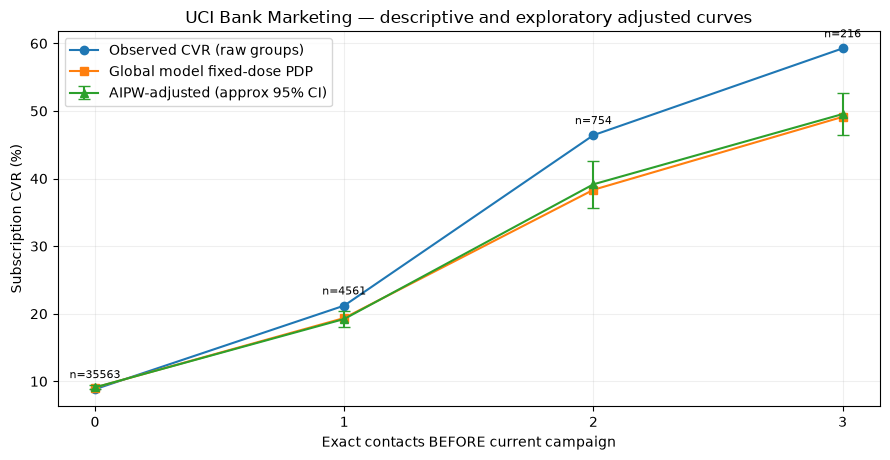

In [33]:
fig, ax = plt.subplots(figsize=(9,4.7))
ax.plot(DOSES, 100*observed_d.observed.to_numpy(), 'o-', label='Observed CVR (raw groups)')
ax.plot(DOSES, 100*model_curve, 's-', label='Global model fixed-dose PDP')
ax.errorbar(DOSES,100*aipw_curve,yerr=1.96*100*se_d,fmt='^-',capsize=4,
            label='AIPW-adjusted (approx 95% CI)')
for j,d in enumerate(DOSES):
    ax.annotate(f'n={counts_d[j]}', (d,100*observed_d.observed.iloc[j]),
                xytext=(0,8), textcoords='offset points',fontsize=8,ha='center')
ax.set(xticks=DOSES, xlabel='Exact contacts BEFORE current campaign',
       ylabel='Subscription CVR (%)',
       title='UCI Bank Marketing — descriptive and exploratory adjusted curves')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

## 13 · Dose-specific overlap, effective sample size and propensity-floor sensitivity

Multiclass treatment makes overlap harder: few records might receive exactly 2 or 3 previous contacts. Inspect **actual counts**, the estimated $P(D=d\mid X)$ among receivers, extreme weights, and weighted ESS. Treat estimates for poorly supported doses as highly uncertain or unsuitable for decision-making.

AIPW can even report values **outside [0%,100%]** in sparse small samples because its score isn't constrained to be a probability. That's a warning, not a valid negative subscription rate.

In [34]:
rows=[]
for j,d in enumerate(DOSES):
    got = D_d==d
    w = 1/safe_prop[got,j]
    rows.append({'dose':int(d), 'n_receivers':int(got.sum()),
                 'median_P_d_among_receivers':np.median(prop_d[got,j]),
                 'fraction_all_P_d_below_0.025':(prop_d[:,j]<.025).mean(),
                 'max_used_weight':w.max(), 'ESS':effective_n(w)})
display(pd.DataFrame(rows).round(4))

sensitivity=[]
for floor in [.005,.01,.025,.05]:
    scenario = mu_d + hit*(Y_d[:,None]-mu_d)/np.maximum(prop_d,floor)
    result = scenario.mean(axis=0)
    sensitivity.append({'floor':floor,**{f'AIPW_d{d}_pct':100*result[j] for j,d in enumerate(DOSES)}})
display(pd.DataFrame(sensitivity).round(3))
print('If estimates change materially, do not trust a precise dose-specific causal interpretation.')

,dose,n_receivers,median_P_d_among_receivers,fraction_all_P_d_below_0.025,max_used_weight,ESS
0,0,35563,0.8639,0.0000,2.1919,35408.1199
1,1,4561,0.1205,0.0000,26.9139,4062.0375
2,2,754,0.0219,0.8253,100.0000,573.5538
3,3,216,0.0079,0.9797,100.0000,198.5712


,floor,AIPW_d0_pct,AIPW_d1_pct,AIPW_d2_pct,AIPW_d3_pct
0,0.005,9.102,19.224,38.530,49.940
1,0.010,9.102,19.224,39.149,49.542
2,0.025,9.102,19.224,39.340,49.177
3,0.050,9.102,19.226,38.667,49.097


If estimates change materially, do not trust a precise dose-specific causal interpretation.


# PART III · Bonus: one global numeric PLR slope per extra previous contact

If we treat the actual **count** as numeric, PLR estimates a single additive slope rather than a nonlinear curve:

$$
\hat\theta_{count}=\frac{\sum_i\big(D_i-\widehat{E}[D\mid X_i]\big)\big(Y_i-\widehat{E}[Y\mid X_i]\big)}{\sum_i\big(D_i-\widehat{E}[D\mid X_i]\big)^2}
$$

Interpret $\theta_{count}=0.02$ as **+2 pp per additional call under a valid linear/additive causal model**. Here we fit on all observed counts (including high-count tail values), so outlying counts can strongly affect this **single slope**. It is **not** the slope of the discrete AIPW curve or evidence that contact count has a real constant causal effect. The dose is count-valued, not a continuously divisible price.

In [36]:
rY, rD = np.empty(n_d), np.empty(n_d)
for train, test in cv_d.split(X_d,G_d):
    m_y = classifier().fit(X_d.iloc[train], Y_d[train])
    m_d = numeric_regressor().fit(X_d.iloc[train], D_d[train])
    rY[test] = Y_d[test]-m_y.predict_proba(X_d.iloc[test])[:,1]
    rD[test] = D_d[test]-m_d.predict(X_d.iloc[test])

numeric_theta = (rD*rY).sum()/(rD*rD).sum()
numeric_phi = rD*(rY-numeric_theta*rD)/(rD*rD).mean()
numeric_se = numeric_phi.std(ddof=1)/np.sqrt(n_d)
print(f'Observed previous count: median={np.median(D_d):g}, '
      f'99th percentile={np.quantile(D_d,.99):g}, max={D_d.max()}')
print(f'Numeric PLR = {100*numeric_theta:+.2f} pp per additional previous contact')
print(f'Approx CI: [{100*(numeric_theta-1.96*numeric_se):+.2f}, '
      f'{100*(numeric_theta+1.96*numeric_se):+.2f}] pp/call')

Observed previous count: median=0, 99th percentile=2, max=7
Numeric PLR = +13.00 pp per additional previous contact
Approx CI: [+12.10, +13.90] pp/call


# PART IV · How to present findings responsibly

## 14 · Which method for which question?

| Your question | Show first | Additional model | What you may safely say here |
|---|---|---|---|
| What fraction subscribed after $d$ past contacts? | **Observed CVR** and Wilson CI | None required | Descriptive subscription rates |
| Are any past contacts associated with subscription? | Raw binary gap, Newcombe CI | PLR and IRM/AIPW | Proxy-adjusted association, **not validated causal effect** |
| What does the global CVR model predict at 0/1/2/3? | Fixed-dose PDP curve | One pooled logistic CVR model | Model sensitivity, not causal |
| How does weighting actual outcomes modify PDP? | AIPW = PDP + correction | Multinomial propensity and same outcome predictions | Exploratory, support-dependent adjusted curve |
| One straight-line relationship per extra call? | Numeric PLR | Outcome + dose prediction models | Model-dependent slope, not causal proof |

### The scientific verdict for this dataset

1. The bank's assignment of **earlier contacts wasn't randomized**. We lack the complete assignment rule, historical time snapshots, and important customer motivations.
2. All observed records are from **current marketing contacts**; there is no untouched current-campaign customer group. The outcome is **subscription after being contacted**, not spontaneous subscription without contact.
3. The released rows do not establish independent unique customer units. CIs assume independence unless adjusted using suitable IDs, which aren't available here.
4. Cross-fitting protects from model overfit during score estimation, but cannot fix bad causal identification. **Never label our printed values 'number of subscriptions caused by prior calls.'**

## 15 · What a stronger future bank study would collect

**To estimate the incremental effect of contacting at all:** From an eligible pre-campaign customer list, randomize outreach versus no-outreach, define a fixed outcome follow-up period, and compare subscription rates by **assigned policy (intention-to-treat)**. Respect privacy, regulatory obligations and customer contact preferences.

**To estimate the effect of multiple contacts:** Randomize **planned contact policies** (e.g. zero, one, or two allowed call attempts) among eligible customers, record assignment and attempted/actual calls separately, use pre-randomization segmentation if useful, follow every randomized customer, and report confidence intervals and compliance. Do not simply reinterpret actual achieved call counts as randomized doses.

**Minimum logging:** stable `customer_id`, eligibility date, baseline customer attributes **before randomization**, assignment probability/policy version, intervention timing, contact attempts, actual reach, outcomes and follow-up window. Track potential interference, duplicates, attrition and campaign-period changes.

## 16 · Check you understand (answers included)

**Q1.** If `previous=0`, was a customer never called? **No.** They were contacted in the current campaign; zero refers to calls **before** it.

**Q2.** If observed CVR at 2 contacts is 25% and at 0 is 9%, what is the raw gap? **+16 pp**, not proven causal lift.

**Q3.** Where do $\mu_0$ and $\mu_1$ come from? From **separate outcome models** trained on fold-training records with $T=0$ and $T=1$ respectively; both predict the **same held-out customers**.

**Q4.** Is fixed-dose PDP just the observed CVR at dose 2? **No.** PDP predicts **all study records** after fixing their past-contact count to 2. Observed CVR uses only records that actually had 2.

**Q5.** Why does AIPW have a $1/n$ factor? It averages the **weighted errors over the whole study population**; it already includes the fraction assigned a dose. No extra $n_d/n$ multiplication.

**Q6.** Does AIPW always improve the estimate? **No.** Rare doses and propensity weights can produce high variance; unmeasured confounding remains.

**Q7.** Is numeric PLR the same as the 0–3 AIPW curve? **No.** PLR assumes one additive linear coefficient; AIPW estimates a separate dose-specific outcome mean.

## 17 · Technical references and next research steps

- [UCI Bank Marketing data documentation](https://archive.ics.uci.edu/dataset/222/bank+marketing) — exact meaning of `previous`, `campaign`, and current-campaign variables.
- [DoubleML model families](https://docs.doubleml.org/stable/guide/models.html) — PLR, binary IRM, and multivalued APOS.
- [scikit-learn partial dependence](https://scikit-learn.org/stable/modules/partial_dependence.html) — model-based averaging and extrapolation limitations.
- [statsmodels proportion intervals](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html) — Wilson.
- [statsmodels two-proportion intervals](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.confint_proportions_2indep.html) — Newcombe.

**Implementation choice:** We implement cross-fitted PLR and AIPW scores directly with scikit-learn rather than using the DoubleML package, to make every fitted model and correction visible. Multilevel outcomes share one pooled global outcome model rather than fitting a separate binary outcome model per exact dose; that is a **modeling choice**, not an automatic guarantee of flexibility.

**Inference caveat:** The confidence intervals here are introductory approximations; data-selected model forms, propensity floors, and unknown repeated-customer clustering can affect validity. No confidence interval proves a causal assumption.